# Denoising Diffusion probabilistic model

In [1]:
import torch
from diffusers import DDPMPipeline

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

In [2]:
model_id = "google/ddpm-celebahq-256"

image_pipeline = DDPMPipeline.from_pretrained(model_id).to(device)

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /Users/amirhossein/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/amirhossein/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /Users/amirhossein/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/amirhossein/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/1000 [00:00<?, ?it/s]

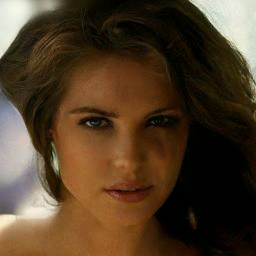

In [ ]:
image_pipeline().images[0]

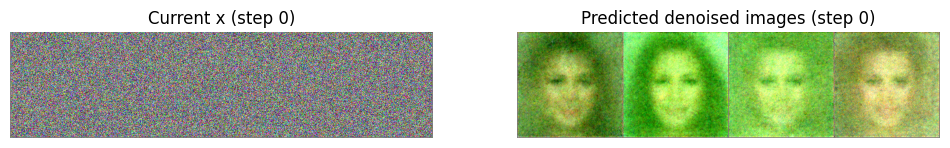

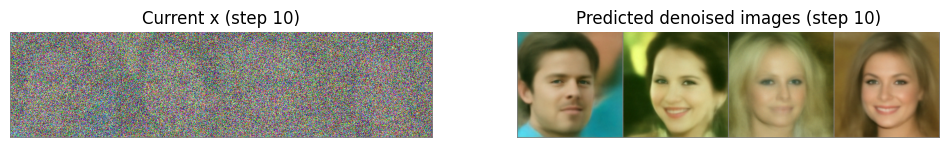

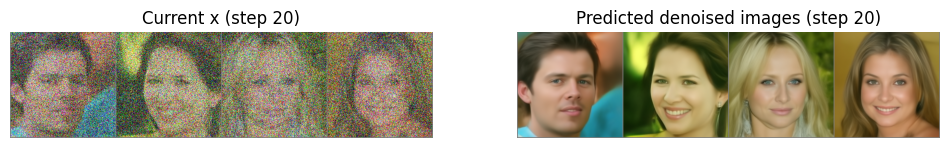

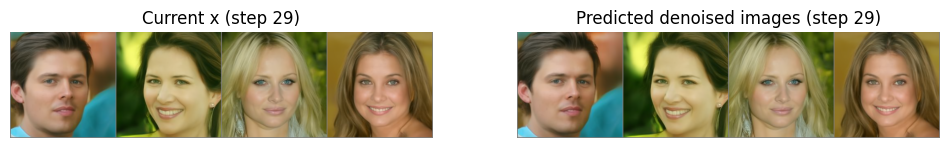

In [3]:
from genaibook.core import plot_noise_and_denoise

image = torch.randn(4, 3, 256, 256).to(device)

image_pipeline.scheduler.set_timesteps(num_inference_steps=30)


for i, t in enumerate(image_pipeline.scheduler.timesteps):
    
    with torch.inference_mode():
        noise_pred = image_pipeline.unet(image, t).sample
      
    scheduler_out = image_pipeline.scheduler.step(noise_pred, t, image)
    image = scheduler_out.prev_sample
    
    if i % 10 == 0 or i == len(image_pipeline.scheduler.timesteps) - 1:
        plot_noise_and_denoise(scheduler_out, i)


In [3]:
from datasets import load_dataset

dataset = load_dataset("huggan/smithsonian_butterflies_subset", split="train")

Repo card metadata block was not found. Setting CardData to empty.


In [4]:
from torchvision import transforms as T

img_size = 64

preprocess = T.Compose([
    T.Resize((img_size, img_size)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),
])

def transform(examples):
    examples = [preprocess(image) for image in examples["image"]]
    return {"images": examples}

dataset.set_transform(transform)
BATCH_SIZE = 32

train_dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

torch.Size([32, 3, 64, 64])


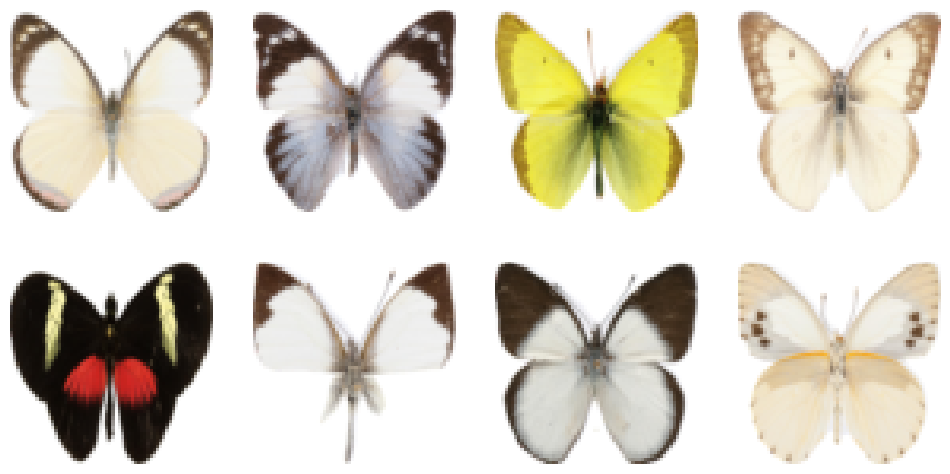

In [5]:
from genaibook.core import show_images

sample_batch = next(iter(train_dataloader))["images"]
print(sample_batch.shape)

show_images(sample_batch[:8] * 0.5 + 0.5)

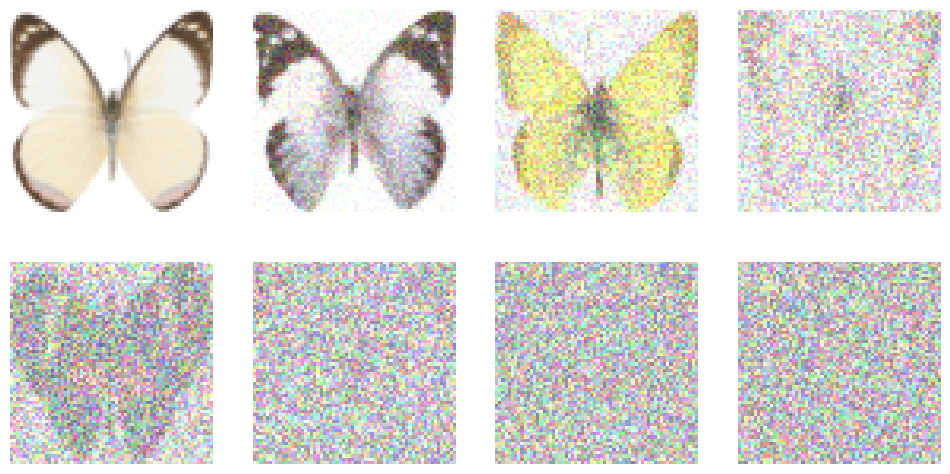

In [6]:
from diffusers import DDPMScheduler

scheduler = DDPMScheduler(num_train_timesteps=1000, beta_start=0.001, beta_end=0.02)

timesteps = torch.linspace(0, 999, 8).long()

x = sample_batch[:8]
noise = torch.rand_like(x)

noised_x = scheduler.add_noise(x, noise, timesteps)

show_images((noised_x * 0.5 + 0.5).clip(0, 1))

In [7]:
from diffusers import UNet2DModel

unet = UNet2DModel(
  sample_size=img_size,
  in_channels=3,
  
  block_out_channels=(64, 128, 256, 512),
  down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
  up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

with torch.inference_mode():
    noise_pred = unet(noised_x.to(device), timesteps.to(device)).sample

print(noised_x.shape)
print(noise_pred.shape)

torch.Size([8, 3, 64, 64])
torch.Size([8, 3, 64, 64])


In [8]:
import torch.nn.functional as F
from tqdm.auto import tqdm

NUM_EPOCHS = 10
LR = 1e-4
optimizer = torch.optim.AdamW(unet.parameters(), lr=LR)

train_loss_hist = []

for epoch in tqdm(range(NUM_EPOCHS)):
    for step, batch in tqdm(enumerate(train_dataloader), total=len(train_dataloader), leave=False):
        optimizer.zero_grad()
        
        x = batch["images"].to(device)
        noise = torch.randn_like(x)
        
        timesteps = torch.randint(0, scheduler.config.num_train_timesteps, (x.shape[0],), device=device).long()
        
        noised_x = scheduler.add_noise(x, noise, timesteps)
        
        noise_pred = unet(noised_x, timesteps, return_dict=False)[0]
        
        loss = F.mse_loss(noise_pred, noise)
        
        loss.backward()
        optimizer.step()
        train_loss_hist.append(loss.item())

    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} - Loss: {loss.item():.4f}")

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/10 - Loss: 0.1095


  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 2/10 - Loss: 0.1207


...

Epoch 8/10 - Loss: 0.1187


  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 9/10 - Loss: 0.0236


  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 10/10 - Loss: 0.0203


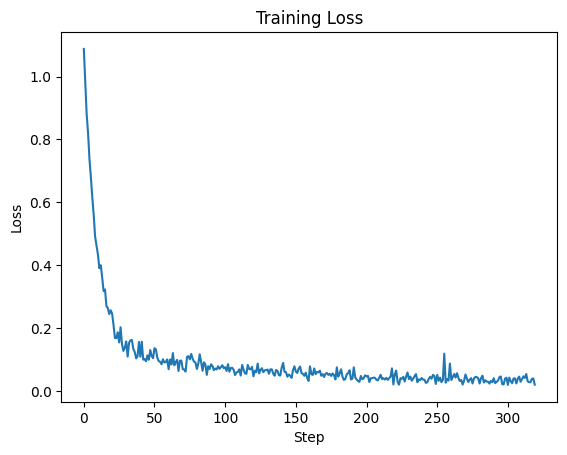

In [9]:
from matplotlib import pyplot as plt

plt.plot(train_loss_hist)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

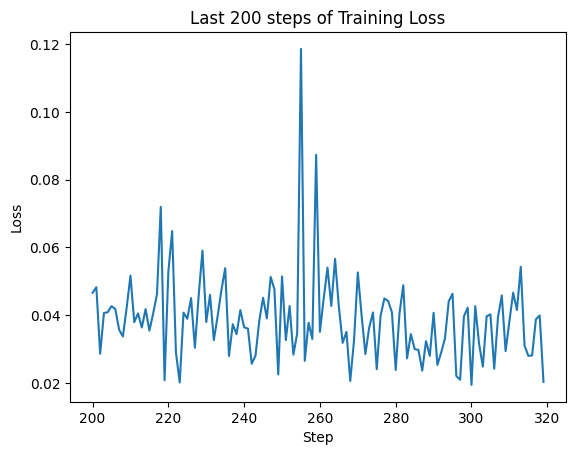

In [14]:
plt.plot(range(200, len(train_loss_hist)), train_loss_hist[200:])
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Last 200 steps of Training Loss")
plt.show()